In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [5]:
img = cv2.imread('data/giraffe-Kenya.png')

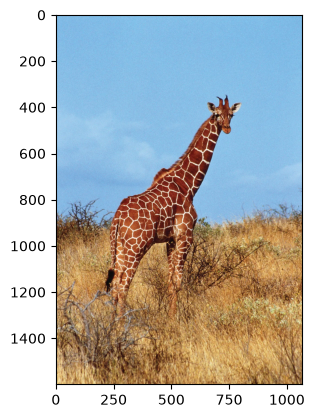

In [4]:
# Image in RGB format
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb)

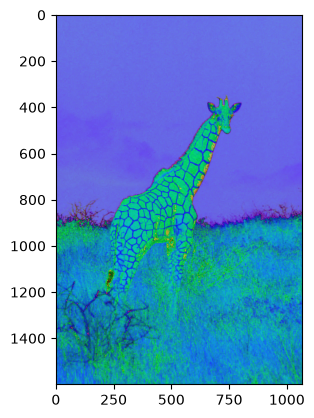

In [6]:
# Image in HSV format
img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
plt.imshow(img_hsv)

In [10]:
lower_white = np.array([0,0,190])
upper_white = np.array([30,80,255])

mask = cv2.inRange(src=img_hsv, lowerb=lower_white, upperb=upper_white)
np.unique(mask, return_counts=True)

(array([  0, 255], dtype=uint8), array([1682388,   24812]))

For each pixel, OpenCV checks whether all three conditions are satisfied:
- $(0 \leq H \leq 30)$
- $(0 \leq S \leq 80)$
- $(190 \leq V \leq 255)$
  
If all three conditions are true, the output pixel is `255` (white). Otherwise, it is `0` (black).

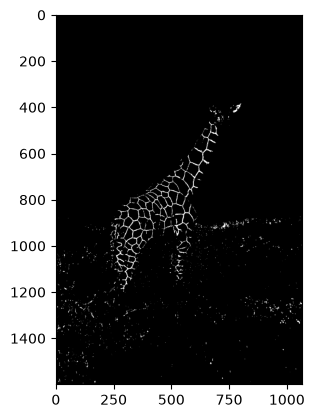

In [13]:
plt.imshow(mask, 'gray')

In [17]:
black_hsv = np.uint8([[[120,255,0]]]) # must have 3 channels (3-dimension)
black_bgr = cv2.cvtColor(black_hsv, cv2.COLOR_HSV2BGR)[0][0]
black_bgr

array([0, 0, 0], dtype=uint8)

In [13]:
black_hsv = np.uint8([[[120, 255, 0]]])
black_bgr = cv2.cvtColor(black_hsv, cv2.COLOR_HSV2BGR)[0][0]

In [14]:
image_result = image.copy()
image_result[mask>0] = black_bgr

In [15]:
image_result_rgb = cv2.cvtColor(image_result, cv2.COLOR_BGR2RGB)

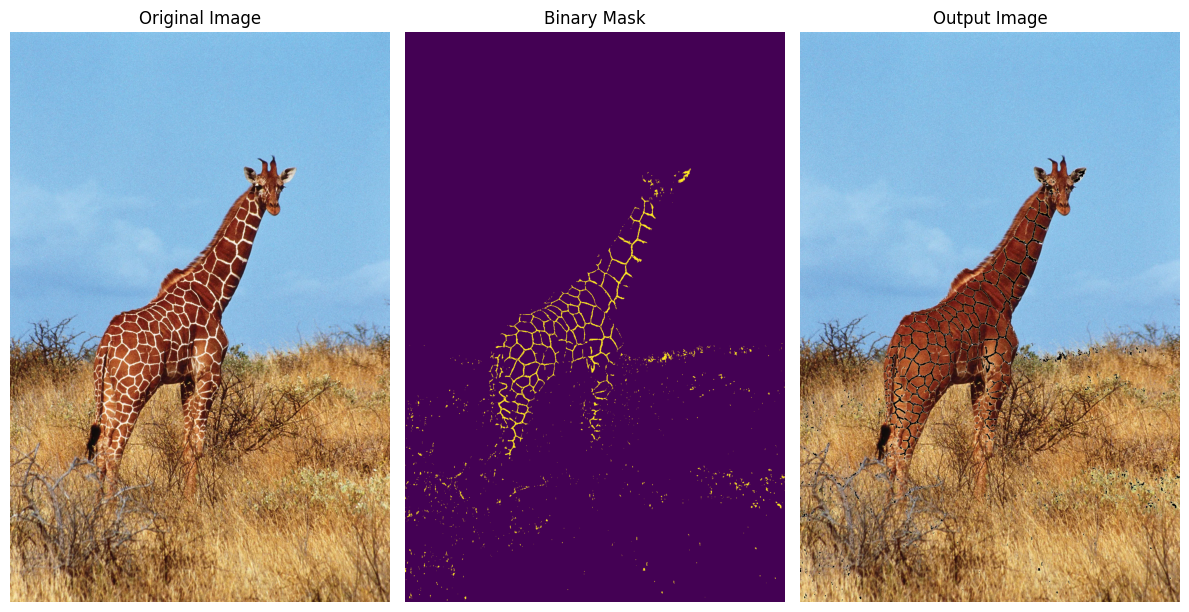

In [17]:
# PLOT

fig, axs = plt.subplots(1,3, figsize=(12,6))

axs[0].imshow(image_rgb)
axs[0].set_title("Original Image")
axs[0].axis('off')

axs[1].imshow(mask)
axs[1].set_title("Binary Mask")
axs[1].axis('off')


axs[2].imshow(image_result_rgb)
axs[2].set_title("Output Image")
axs[2].axis('off')

plt.tight_layout()
plt.show()

# 